# Import Library

In [ ]:
import os
import glob
import tensorflow as tf
from train_dual import train_mobilenet,CoDAModel, make_backbone,evaluate_model


2025-09-08 08:26:03.795949: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1757294763.925236     821 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1757294763.966144     821 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-09-08 08:26:04.332467: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# Get ENV file

In [ ]:
import os
from dotenv import load_dotenv

# Load environment.env file
load_dotenv("environment.env")

# Quick check (optional)

print("Source dataset:", os.environ["S_DSET_PATH"])
print("Target dataset:", os.environ["T_DSET_PATH"])
print("Test dataset:", os.environ["TEST_DSET_PATH"])
print("Epochs:", os.environ["EPOCH"])


Source dataset: /mnt/c/KULIAH_S007/DomainAdaptation_Thesis/ISIC2019_merged
Target dataset: /mnt/c/KULIAH_S007/DomainAdaptation_Thesis/fitz_unlabeled/dummy
Test dataset: /mnt/c/KULIAH_S007/DomainAdaptation_Thesis/fitz_selected
Epochs: 50


In [ ]:
load_dotenv("/mnt/data/environment.env")

from train_dual import make_datasets, make_backbone, CoDAModel, evaluate_model, train_mobilenet

# Dataset paths & params
source_dir = os.getenv("S_DSET_PATH")
target_dir = os.getenv("T_DSET_PATH")
test_dir   = os.getenv("TEST_DSET_PATH")
batch_size = int(os.getenv("BATCH_SIZE", 4))
num_classes = int(os.getenv("CLASS_NUMBER", 7))

# Build datasets
dual_ds, test_ds, class_names = make_datasets(source_dir, target_dir, test_dir, batch_size=batch_size)

print(" Dataset ready")
print("Class names:", class_names)

Found 25078 files belonging to 7 classes.


I0000 00:00:1757294812.006158     821 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1768 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 2059 files belonging to 7 classes.
✅ Dataset ready
Class names: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']


# Train (4 Batch)

In [ ]:
history = train_mobilenet()


Found 25078 files belonging to 7 classes.
Found 2059 files belonging to 7 classes.
Epoch 1/50


I0000 00:00:1757179693.468037   32291 service.cc:148] XLA service 0x732208005e70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1757179693.468090   32291 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6
2025-09-07 00:28:14.942141: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1757179699.543249   32291 cuda_dnn.cc:529] Loaded cuDNN version 91100
2025-09-07 00:28:22.308773: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10201', 8 bytes spill stores, 8 bytes spill loads

2025-09-07 00:28:22.529508: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10201

514/515 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.5007 - loss: 2.4850

2025-09-07 00:29:57.703917: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng3{k11=2} for conv (f32[1,576,14,14]{3,2,1,0}, u8[0]{0}) custom-call(f32[1,576,14,14]{3,2,1,0}, f32[576,1,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, feature_group_count=576, custom_call_target="__cudnn$convForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]} is taking a while...
2025-09-07 00:29:57.947699: E external/local_xla/xla/service/slow_operation_alarm.cc:133] The operation took 1.244909788s
Trying algorithm eng3{k11=2} for conv (f32[1,576,14,14]{3,2,1,0}, u8[0]{0}) custom-call(f32[1,576,14,14]{3,2,1,0}, f32[576,1,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, feature_group_count=576, custom_call_target="__cudnn$convForward", backend_con

515/515 ━━━━━━━━━━━━━━━━━━━━ 171s 182ms/step - accuracy: 0.5009 - loss: 2.4821 - val_val_accuracy: 0.1642 - val_val_f1: 0.1361 - val_val_loss: 2.7793 - val_val_precision: 0.1935 - val_val_recall: 0.1049 - learning_rate: 1.0000e-04
Epoch 2/50


/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/keras/src/callbacks/early_stopping.py:153: UserWarning: Early stopping conditioned on metric `val_accuracy` which is not available. Available metrics are: accuracy,loss,val_val_accuracy,val_val_f1,val_val_loss,val_val_precision,val_val_recall
  current = self.get_monitor_value(logs)
/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/keras/src/callbacks/callback_list.py:145: UserWarning: Learning rate reduction is conditioned on metric `val_accuracy` which is not available. Available metrics are: accuracy,loss,val_val_accuracy,val_val_f1,val_val_loss,val_val_precision,val_val_recall,learning_rate.
  callback.on_epoch_end(epoch, logs)


515/515 ━━━━━━━━━━━━━━━━━━━━ 54s 105ms/step - accuracy: 0.6385 - loss: 2.1022 - val_val_accuracy: 0.1481 - val_val_f1: 0.1320 - val_val_loss: 3.8986 - val_val_precision: 0.1754 - val_val_recall: 0.1059 - learning_rate: 1.0000e-04
Epoch 3/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 54s 102ms/step - accuracy: 0.6591 - loss: 1.9373 - val_val_accuracy: 0.1559 - val_val_f1: 0.1502 - val_val_loss: 4.6118 - val_val_precision: 0.1970 - val_val_recall: 0.1214 - learning_rate: 1.0000e-04
Epoch 4/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 55s 104ms/step - accuracy: 0.7106 - loss: 1.7119 - val_val_accuracy: 0.1374 - val_val_f1: 0.1271 - val_val_loss: 4.3617 - val_val_precision: 0.1519 - val_val_recall: 0.1093 - learning_rate: 1.0000e-04
Epoch 5/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 61s 116ms/step - accuracy: 0.7658 - loss: 1.5089 - val_val_accuracy: 0.1831 - val_val_f1: 0.1283 - val_val_loss: 2.9973 - val_val_precision: 0.2214 - val_val_recall: 0.0903 - learning_rate: 1.0000e-04
Epoch 6/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 53s 100

# Load Model

In [ ]:
print("len(class_names):", len(class_names))
print("Expected num_classes:", os.getenv("CLASS_NUMBER"))


# Reload trained model for evaluation
net1 = make_backbone(len(class_names))
net2 = make_backbone(len(class_names))
coda_model = CoDAModel(net1, net2, num_classes=len(class_names))
coda_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4))
coda_model.build(input_shape=[((None,224,224,3),(None,len(class_names))), (None,224,224,3)])
coda_model.load_weights("Model_TF2/20250907_002657/best_coda_model.weights.h5")




len(class_names): 7
Expected num_classes: 7


/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 634 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


# Evaluate

In [ ]:
# Evaluate
evaluate_model(coda_model, test_ds, class_names)

              precision    recall  f1-score   support

          ak       0.00      0.00      0.00       175
         bcc       0.41      0.25      0.31       500
         bkl       0.06      0.55      0.10        69
          df       0.12      0.03      0.04        79
         mel       0.32      0.36      0.34       500
          nv       0.21      0.35      0.27       236
         scc       0.52      0.13      0.21       500

    accuracy                           0.24      2059
   macro avg       0.23      0.24      0.18      2059
weighted avg       0.34      0.24      0.24      2059



2025-09-07 05:17:02.971984: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


I0000 00:00:1757237688.647803     742 cuda_dnn.cc:529] Loaded cuDNN version 91100
2025-09-07 16:42:23.474385: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


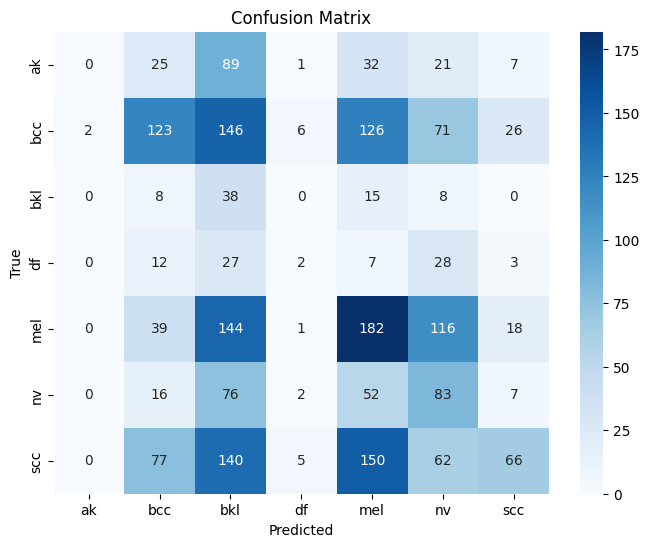

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Collect predictions
y_true, y_pred = [], []
for batch_x, batch_y in test_ds:
    logits1 = coda_model.net1(batch_x, training=False)
    logits2 = coda_model.net2(batch_x, training=False)
    avg_logits = (logits1 + logits2) / 2.0
    preds = tf.argmax(avg_logits, axis=1).numpy()
    labels = tf.argmax(batch_y, axis=1).numpy()
    y_pred.extend(preds)
    y_true.extend(labels)

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


# Predict

Found 25078 files belonging to 7 classes.
Found 2059 files belonging to 7 classes.


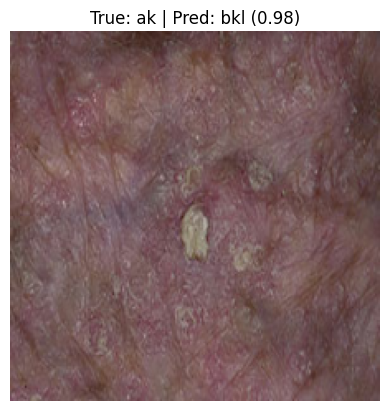

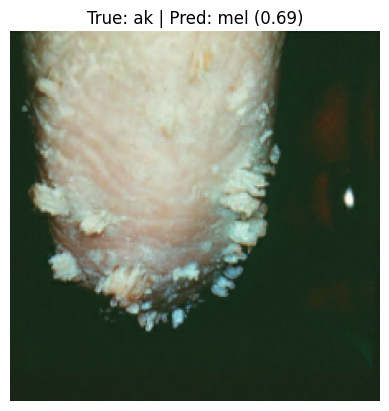

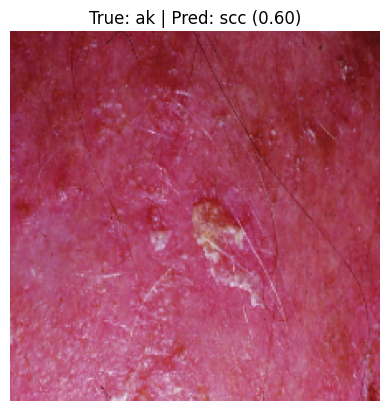

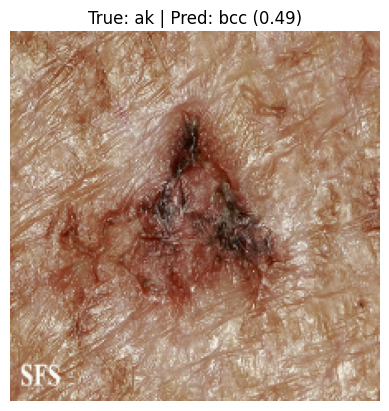

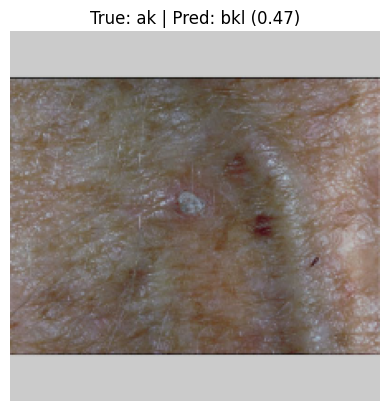

2025-09-07 17:43:57.087791: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [ ]:
_, test_ds, class_names = make_datasets(
    os.environ.get("S_DSET_PATH"),
    os.environ.get("T_DSET_PATH"),
    os.environ.get("TEST_DSET_PATH"),
    batch_size=1
)

for images, labels in test_ds.take(5):  # show 5 samples
    logits1 = coda_model.net1(images, training=False)
    logits2 = coda_model.net2(images, training=False)
    avg_logits = (logits1 + logits2) / 2.0
    probs = tf.nn.softmax(avg_logits, axis=-1)

    pred_class = tf.argmax(probs, axis=-1).numpy()[0]
    true_class = tf.argmax(labels, axis=-1).numpy()[0]

    plt.imshow(images[0].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_class]} | Pred: {class_names[pred_class]} ({probs[0][pred_class]:.2f})")
    plt.show()


# Train (4 Batch - Optimized)

In [ ]:
history = train_mobilenet()


Found 25078 files belonging to 7 classes.
Found 2059 files belonging to 7 classes.
Epoch 1/50


I0000 00:00:1757253123.075964    1114 service.cc:148] XLA service 0x7a3998007a20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1757253123.076352    1114 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6
2025-09-07 20:52:04.302590: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1757253130.974892    1114 cuda_dnn.cc:529] Loaded cuDNN version 91100
2025-09-07 20:52:13.875830: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10201', 8 bytes spill stores, 8 bytes spill loads

2025-09-07 20:52:14.008765: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10201

515/515 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.1140 - loss: -1.3485

E0000 00:00:1757253238.311521    1113 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1757253238.523390    1113 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/keras/src/callbacks/model_checkpoint.py:302: UserWarning: Can save best model only with val_f1 available.
  if self._should_save_model(epoch, batch, logs, filepath):


515/515 ━━━━━━━━━━━━━━━━━━━━ 181s 188ms/step - accuracy: 0.1140 - loss: -1.3486 - val_val_accuracy: 0.0437 - val_val_f1: 0.0309 - val_val_loss: 3.2630 - val_val_precision: 0.0457 - val_val_recall: 0.0233 - learning_rate: 1.0000e-04
Epoch 2/50


...

515/515 ━━━━━━━━━━━━━━━━━━━━ 52s 99ms/step - accuracy: 0.1402 - loss: -1.3863 - val_val_accuracy: 0.2098 - val_val_f1: 0.2102 - val_val_loss: 0.0000e+00 - val_val_precision: 0.2115 - val_val_recall: 0.2088 - learning_rate: 1.0000e-04
Epoch 49/50


2025-09-07 21:37:02.382027: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 2408448 bytes after encountering the first element of size 2408448 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
2025-09-07 21:37:02.382156: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 4817152 bytes after encountering the first element of size 4817152 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


515/515 ━━━━━━━━━━━━━━━━━━━━ 55s 103ms/step - accuracy: 0.1495 - loss: -1.3863 - val_val_accuracy: 0.2249 - val_val_f1: 0.2254 - val_val_loss: 0.0000e+00 - val_val_precision: 0.2259 - val_val_recall: 0.2249 - learning_rate: 1.0000e-04
Epoch 50/50


2025-09-07 21:37:57.020145: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 2408448 bytes after encountering the first element of size 2408448 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
2025-09-07 21:37:57.020289: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 4817152 bytes after encountering the first element of size 4817152 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


515/515 ━━━━━━━━━━━━━━━━━━━━ 55s 104ms/step - accuracy: 0.1570 - loss: -1.3863 - val_val_accuracy: 0.2186 - val_val_f1: 0.2184 - val_val_loss: 0.0000e+00 - val_val_precision: 0.2192 - val_val_recall: 0.2176 - learning_rate: 1.0000e-04


# Load Model

In [ ]:
print("len(class_names):", len(class_names))
print("Expected num_classes:", os.getenv("CLASS_NUMBER"))


# Reload trained model for evaluation
net1 = make_backbone(len(class_names))
net2 = make_backbone(len(class_names))
coda_model = CoDAModel(net1, net2, num_classes=len(class_names))
coda_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4))
coda_model.build(input_shape=[((None,224,224,3),(None,len(class_names))), (None,224,224,3)])
coda_model.load_weights("Model_TF2/20250907_205046/best_coda_model.weights.h5")




len(class_names): 7
Expected num_classes: 7


/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 634 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


# Evaluate

In [ ]:
# Evaluate
evaluate_model(coda_model, test_ds, class_names)

              precision    recall  f1-score   support

          ak       0.00      0.00      0.00       175
         bcc       0.00      0.00      0.00       500
         bkl       0.01      0.04      0.02        69
          df       0.02      0.01      0.01        79
         mel       0.00      0.00      0.00       500
          nv       0.05      0.01      0.01       236
         scc       0.25      0.89      0.40       500

    accuracy                           0.22      2059
   macro avg       0.05      0.14      0.06      2059
weighted avg       0.07      0.22      0.10      2059



2025-09-07 21:54:27.851317: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/sklearn/metrics/_classification.p

2025-09-08 08:55:33.873072: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


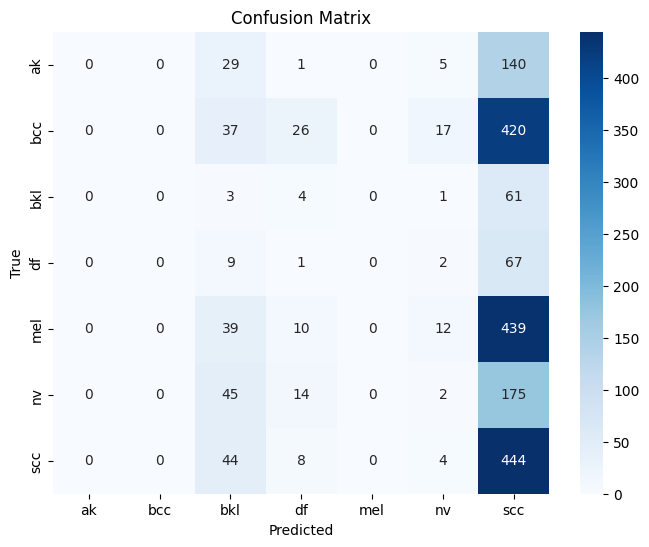

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Collect predictions
y_true, y_pred = [], []
for batch_x, batch_y in test_ds:
    logits1 = coda_model.net1(batch_x, training=False)
    logits2 = coda_model.net2(batch_x, training=False)
    avg_logits = (logits1 + logits2) / 2.0
    preds = tf.argmax(avg_logits, axis=1).numpy()
    labels = tf.argmax(batch_y, axis=1).numpy()
    y_pred.extend(preds)
    y_true.extend(labels)

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


# Predict

Found 25078 files belonging to 7 classes.
Found 2059 files belonging to 7 classes.


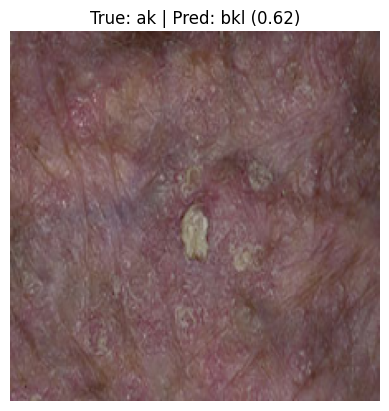

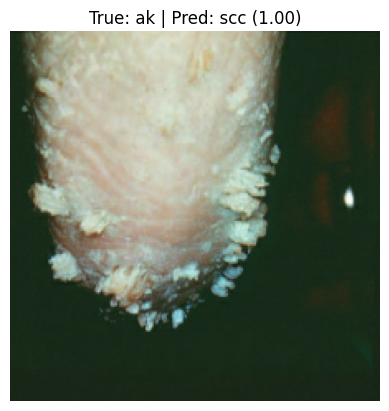

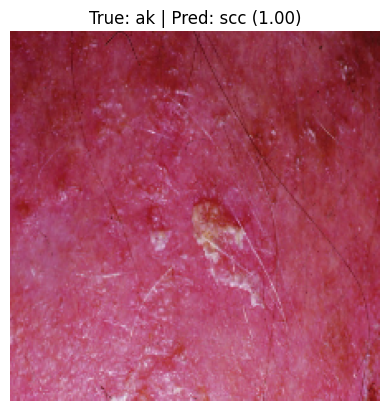

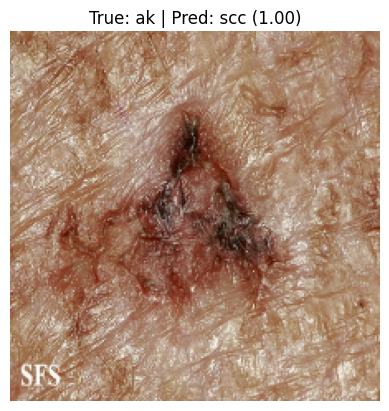

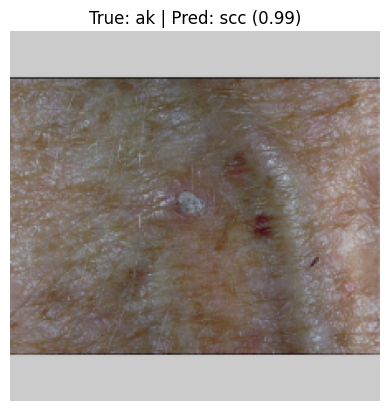

2025-09-08 08:56:16.830589: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [ ]:
_, test_ds, class_names = make_datasets(
    os.environ.get("S_DSET_PATH"),
    os.environ.get("T_DSET_PATH"),
    os.environ.get("TEST_DSET_PATH"),
    batch_size=1
)

for images, labels in test_ds.take(5):  # show 5 samples
    logits1 = coda_model.net1(images, training=False)
    logits2 = coda_model.net2(images, training=False)
    avg_logits = (logits1 + logits2) / 2.0
    probs = tf.nn.softmax(avg_logits, axis=-1)

    pred_class = tf.argmax(probs, axis=-1).numpy()[0]
    true_class = tf.argmax(labels, axis=-1).numpy()[0]

    plt.imshow((images[0].numpy() * 255).astype("uint8"))  # ✅ scale back for visualization
    plt.axis("off")
    plt.title(f"True: {class_names[true_class]} | Pred: {class_names[pred_class]} ({probs[0][pred_class]:.2f})")
    plt.show()



# Proceed Train

In [ ]:
tf.config.run_functions_eagerly(True)
history = train_mobilenet()


Found 25078 files belonging to 7 classes.


I0000 00:00:1757090593.079459   11594 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1768 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6
/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


Found 2059 files belonging to 7 classes.
Epoch 1/50


I0000 00:00:1757090599.956925   11594 cuda_dnn.cc:529] Loaded cuDNN version 91100


515/515 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5085 - loss: 2.4598

/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/keras/src/callbacks/model_checkpoint.py:302: UserWarning: Can save best model only with val_accuracy available.
  if self._should_save_model(epoch, batch, logs, filepath):
/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/keras/src/saving/saving_api.py:107: UserWarning: You are saving a model that has not yet been built. It might not contain any weights yet. Consider building the model first by calling it on some data.
  return saving_lib.save_model(model, filepath)


515/515 ━━━━━━━━━━━━━━━━━━━━ 1546s 3s/step - accuracy: 0.5086 - loss: 2.4591 - val_val_accuracy: 0.2205 - val_val_f1: 0.2083 - val_val_loss: 4.3671 - val_val_precision: 0.2690 - val_val_recall: 0.1700
Epoch 2/50


/home/yonat/projects/DomainAdaptation_Thesis/tf-gpu310/lib/python3.10/site-packages/keras/src/callbacks/early_stopping.py:153: UserWarning: Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: accuracy,loss,val_val_accuracy,val_val_f1,val_val_loss,val_val_precision,val_val_recall
  current = self.get_monitor_value(logs)


515/515 ━━━━━━━━━━━━━━━━━━━━ 1559s 3s/step - accuracy: 0.6258 - loss: 2.1365 - val_val_accuracy: 0.1884 - val_val_f1: 0.1692 - val_val_loss: 4.0518 - val_val_precision: 0.2141 - val_val_recall: 0.1399
Epoch 3/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 1544s 3s/step - accuracy: 0.6622 - loss: 1.9710 - val_val_accuracy: 0.1972 - val_val_f1: 0.1692 - val_val_loss: 4.9422 - val_val_precision: 0.2307 - val_val_recall: 0.1336
Epoch 4/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 1530s 3s/step - accuracy: 0.7132 - loss: 1.7545 - val_val_accuracy: 0.1850 - val_val_f1: 0.1612 - val_val_loss: 6.8010 - val_val_precision: 0.2105 - val_val_recall: 0.1306
Epoch 5/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 1539s 3s/step - accuracy: 0.7570 - loss: 1.5505 - val_val_accuracy: 0.1530 - val_val_f1: 0.1249 - val_val_loss: 5.3830 - val_val_precision: 0.1734 - val_val_recall: 0.0976
Epoch 6/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 1538s 3s/step - accuracy: 0.8110 - loss: 1.3640 - val_val_accuracy: 0.1773 - val_val_f1: 0.1452 - val_val_loss: 5.9539 - va

# Plot train matrix

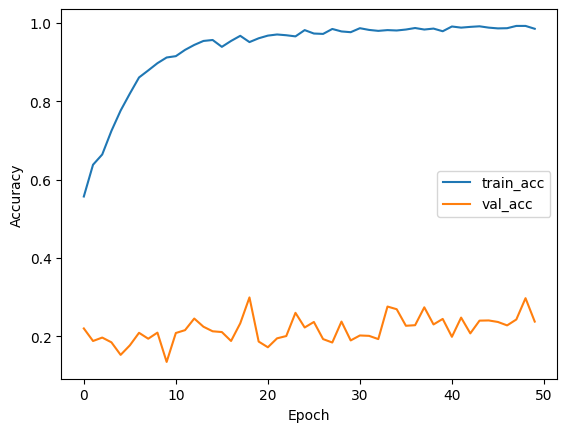

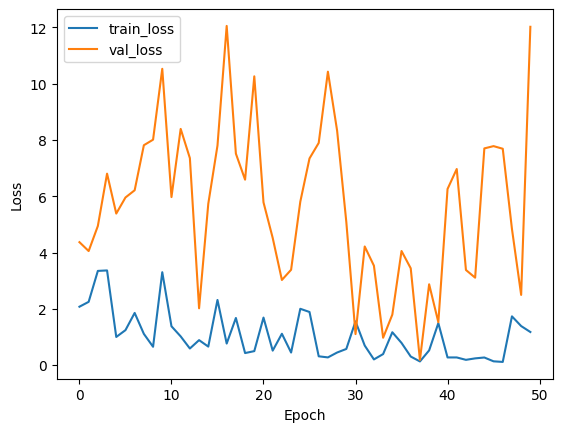

In [ ]:
import matplotlib.pyplot as plt

# Plot training/validation accuracy
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_val_accuracy'], label='val_acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training/validation loss
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


# Performance evaluation

In [ ]:
import os
import tensorflow as tf
from train_dual import make_datasets, CoDAModel, make_backbone, evaluate_model

# Load environment variables
from dotenv import load_dotenv
load_dotenv("/mnt/data/environment.env")

source_dir = os.getenv("S_DSET_PATH")
target_dir = os.getenv("T_DSET_PATH")
test_dir   = os.getenv("TEST_DSET_PATH")
batch_size = int(os.getenv("BATCH_SIZE", 4))

dual_ds, test_ds_raw = make_datasets(source_dir, target_dir, test_dir, batch_size=batch_size)

# Recreate test_ds separately to access class_names
test_loader = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="categorical",
    batch_size=1,
    image_size=(224,224),
    shuffle=False
)

class_names = test_loader.class_names
print("Class names:", class_names)



Found 25078 files belonging to 7 classes.
Found 2059 files belonging to 7 classes.
Found 2059 files belonging to 7 classes.
Class names: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']


In [ ]:
num_classes = int(os.getenv("CLASS_NUMBER", 7))

# Rebuild backbone
net1 = make_backbone(num_classes)
net2 = make_backbone(num_classes)
coda_model = CoDAModel(net1, net2, num_classes=num_classes)

# Compile (same optimizer as training)
coda_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4))

# --- Build model by calling once on dummy data ---
dummy_input = tf.random.normal([1, 224, 224, 3])
_ = coda_model.net1(dummy_input)
_ = coda_model.net2(dummy_input)

# Now load weights
weights_path = "Model_TF2/20250906_220000/final_coda_model.keras"
coda_model.load_weights(weights_path)
print("✅ Weights loaded successfully")


I0000 00:00:1757171846.728614     817 cuda_dnn.cc:529] Loaded cuDNN version 91100


ValueError: You are loading weights into a model that has not yet been built. Try building the model first by calling it on some data or by using `build()`.